# Análisis conjunto · Benchmark de deep learning con pocos datos

Este notebook **no entrena nada**. Lee los CSV que produjo el notebook de cada
modelo (`01` a `04`) y genera las figuras y tablas comparativas del proyecto.

Entradas esperadas:
- `resultados/resultados_cnn/resultados_cnn.csv`
- `resultados/resultados_resnet/resultados_resnet.csv`
- `resultados/resultados_deit/resultados_deit.csv`
- `resultados/resultados_convnext/resultados_convnext.csv`

Y (opcional, para las curvas de entrenamiento) los historiales `.npz` en
`resultados/resultados_<modelo>/predicciones/hist_*.npz`.

Todas las figuras se guardan en `figuras/` en PNG y PDF (vectorial), a 300 dpi.

In [1]:
# setup: carga de los 4 CSV
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RESULTS_ROOT = Path("../resultados")
FIG_DIR = Path("../figuras")
FIG_DIR.mkdir(exist_ok=True)

# nombre para mostrar -> clave interna del csv
MODELOS = {
    "CNN (desde cero)": "cnn",
    "ResNet18": "resnet",
    "DeiT-S": "deit",
    "ConvNeXt-T": "convnext",
}
# orden fijo: sin pretraining primero, luego preentrenados
ORDEN_MODELOS = list(MODELOS.keys())

DATASETS = ["cifar10", "pet", "caltech101"]
NOMBRE_DS = {"cifar10": "CIFAR-10", "pet": "Oxford-IIIT Pet",
             "caltech101": "Caltech-101"}

# paleta consistente en TODAS las figuras (mismo color por modelo)
COLOR = {
    "CNN (desde cero)": "#d62728",   # rojo: el unico sin transfer learning
    "ResNet18":         "#1f77b4",
    "DeiT-S":           "#2ca02c",
    "ConvNeXt-T":       "#9467bd",
}
MARCA = {"CNN (desde cero)": "o", "ResNet18": "s",
         "DeiT-S": "^", "ConvNeXt-T": "D"}


def cargar_todo():
    """Junta los 4 CSV en un solo DataFrame con columna 'modelo' legible."""
    frames = []
    for bonito, key in MODELOS.items():
        ruta = RESULTS_ROOT / f"resultados_{key}" / f"resultados_{key}.csv"
        if not ruta.exists():
            warnings.warn(f"FALTA: {ruta}")
            continue
        d = pd.read_csv(ruta)
        if "aug" not in d.columns:
            d["aug"] = 0
        # dedupe por experimento (incluye aug: baseline y fase 2 son distintos)
        d = d.drop_duplicates(
            subset=["model", "dataset", "train_size", "seed", "aug"],
            keep="last")
        d["modelo"] = bonito
        frames.append(d)
    if not frames:
        raise FileNotFoundError("No se encontró ningún CSV.")
    return pd.concat(frames, ignore_index=True)


df = cargar_todo()

# --- reporte de completitud: que no analicemos sobre datos a medias ---
print("COMPLETITUD (esperado 27 por fase: 3 datasets x 3 tamaños x 3 semillas)\n")
tabla = (df.groupby(["modelo", "aug"]).size()
           .unstack(fill_value=0)
           .rename(columns={0: "baseline", 1: "augmentation"}))
tabla["total"] = tabla.sum(axis=1)
print(tabla.reindex([m for m in ORDEN_MODELOS if m in tabla.index]))

incompletos = [(m, int(a), int(n)) for (m, a), n in
               df.groupby(["modelo", "aug"]).size().items() if n < 27]
if incompletos:
    print("\n⚠ INCOMPLETOS (los análisis de Fase 2 de estos modelos son parciales):")
    for m, a, n in incompletos:
        fase = "augmentation" if a else "baseline"
        print(f"   {m} / {fase}: {n}/27 corridas")
else:
    print("\n✓ Los 4 modelos tienen las 27+27 corridas.")

COMPLETITUD (esperado 27 por fase: 3 datasets x 3 tamaños x 3 semillas)

aug               baseline  augmentation  total
modelo                                         
CNN (desde cero)        27            27     54
ResNet18                27            27     54
DeiT-S                  27            27     54
ConvNeXt-T              27            27     54

✓ Los 4 modelos tienen las 27+27 corridas.


## Utilidades

`resumir()` agrega las 3 semillas en media ± desviación. La desviación **es**
la métrica de estabilidad del entrenamiento.

In [2]:
def resumir(d, por=("modelo", "dataset", "train_size")):
    """media ± std sobre las semillas. La std = estabilidad del entrenamiento."""
    return (d.groupby(list(por))
             .agg(acc=("test_acc", "mean"),   acc_std=("test_acc", "std"),
                  f1=("test_f1_macro", "mean"), f1_std=("test_f1_macro", "std"),
                  gap=("overfitting_gap", "mean"),
                  n=("test_acc", "size"))
             .reset_index())


def guardar(fig, nombre):
    """PNG (para ver) + PDF vectorial, 300 dpi."""
    for ext in ("png", "pdf"):
        fig.savefig(FIG_DIR / f"{nombre}.{ext}", dpi=300, bbox_inches="tight")
    print(f"  guardado: figuras/{nombre}.png y .pdf")


base = df[df["aug"] == 0]     # Fase 1
aug  = df[df["aug"] == 1]     # Fase 2
print(f"baseline: {len(base)} filas | augmentation: {len(aug)} filas")

baseline: 108 filas | augmentation: 108 filas


## Figura 1 — Accuracy vs cantidad de datos (figura principal)

Un panel por dataset, una curva por modelo, barras de error = ±1 std entre
semillas. Responde de un vistazo: **qué arquitectura rinde mejor con pocos
datos, y cómo cambia al aumentarlos.**

El eje Y **no** se comparte entre paneles: la CNN desde cero rinde en un rango
tan distinto que forzar una escala común aplastaría las diferencias entre los
preentrenados. Se indica en el pie de figura.

  guardado: figuras/fig1_accuracy_vs_tamano.png y .pdf


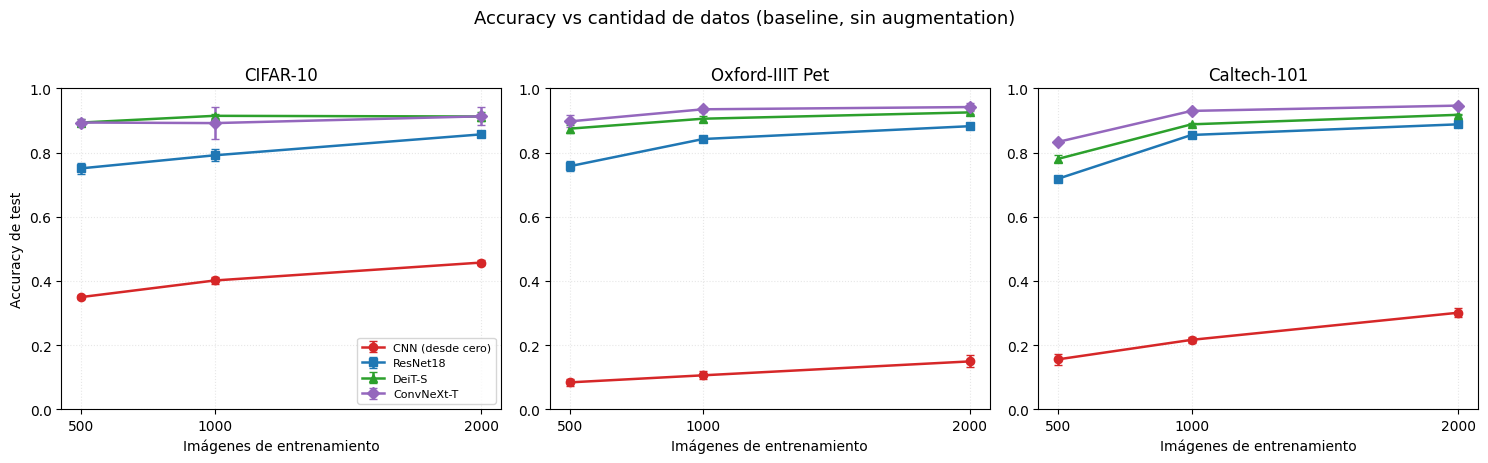


Brecha vs CNN desde cero (puntos de accuracy, tamaño=2000):
  CIFAR-10:
     ResNet18         + 40.0 pts
     DeiT-S           + 45.5 pts
     ConvNeXt-T       + 45.6 pts
  Oxford-IIIT Pet:
     ResNet18         + 73.3 pts
     DeiT-S           + 77.6 pts
     ConvNeXt-T       + 79.3 pts
  Caltech-101:
     ResNet18         + 58.7 pts
     DeiT-S           + 61.7 pts
     ConvNeXt-T       + 64.5 pts


In [3]:
# FIGURA 1: accuracy vs tamaño, por dataset, todas las arquitecturas
res_base = resumir(base)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, ds in zip(axes, DATASETS):
    sub = res_base[res_base["dataset"] == ds]
    for m in ORDEN_MODELOS:
        s = sub[sub["modelo"] == m].sort_values("train_size")
        if not len(s):
            continue
        ax.errorbar(s["train_size"], s["acc"], yerr=s["acc_std"],
                    marker=MARCA[m], color=COLOR[m], capsize=3,
                    linewidth=1.8, markersize=6, label=m)
    ax.set_title(NOMBRE_DS[ds], fontsize=12)
    ax.set_xlabel("Imágenes de entrenamiento")
    ax.set_xticks([500, 1000, 2000])
    ax.grid(alpha=0.3, linestyle=":")
    ax.set_ylim(0, 1.0)
axes[0].set_ylabel("Accuracy de test")
axes[0].legend(fontsize=8, loc="lower right")
fig.suptitle("Accuracy vs cantidad de datos (baseline, sin augmentation)",
             fontsize=13, y=1.02)
plt.tight_layout()
guardar(fig, "fig1_accuracy_vs_tamano")
plt.show()

# la brecha entre preentrenados y la CNN, en numeros
print("\nBrecha vs CNN desde cero (puntos de accuracy, tamaño=2000):")
for ds in DATASETS:
    s = res_base[(res_base["dataset"] == ds) & (res_base["train_size"] == 2000)]
    if "CNN (desde cero)" not in s["modelo"].values:
        continue
    cnn = s[s["modelo"] == "CNN (desde cero)"]["acc"].iloc[0]
    print(f"  {NOMBRE_DS[ds]}:")
    for m in ORDEN_MODELOS[1:]:
        r = s[s["modelo"] == m]
        if len(r):
            print(f"     {m:16} +{(r['acc'].iloc[0]-cnn)*100:5.1f} pts")

## Figura 2 — Efecto del data augmentation por modelo

Delta = accuracy(con augmentation) − accuracy(baseline). Barras sobre cero =
el augmentation ayuda; bajo cero = perjudica.

Esta figura es el corazón del hallazgo: el augmentation **no es universalmente
beneficioso**. Su signo depende de si el modelo tiene una base representacional
(transfer learning) y del tipo de tarea.

  guardado: figuras/fig2_efecto_augmentation.png y .pdf


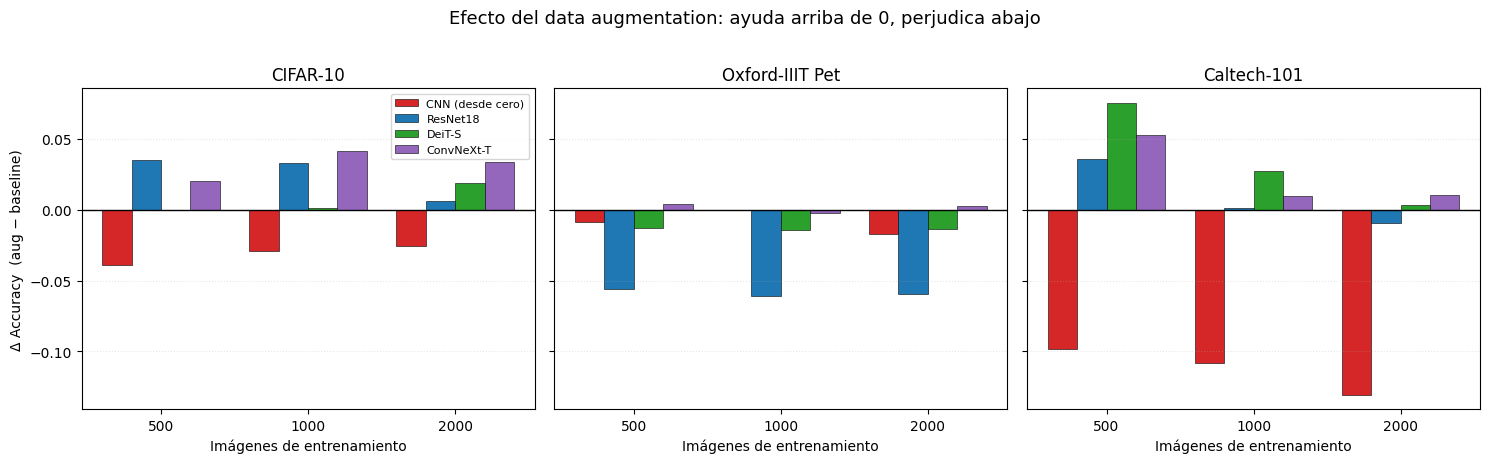


Tabla de deltas (Δ accuracy, en puntos porcentuales):
dataset          caltech101             cifar10            pet          
train_size             500   1000  2000    500  1000 2000 500  1000 2000
modelo                                                                  
CNN (desde cero)       -9.8 -10.8 -13.0    -3.9 -2.9 -2.5 -0.9  0.0 -1.7
ResNet18                3.6   0.1  -1.0     3.5  3.3  0.6 -5.6 -6.1 -6.0
DeiT-S                  7.5   2.7   0.3     0.0  0.1  1.9 -1.3 -1.4 -1.4
ConvNeXt-T              5.2   1.0   1.0     2.0  4.1  3.3  0.4 -0.2  0.3


In [4]:
# FIGURA 2: delta del augmentation (aug - baseline) por modelo y dataset
res_aug = resumir(aug)
m_base = res_base.set_index(["modelo", "dataset", "train_size"])
m_aug  = res_aug.set_index(["modelo", "dataset", "train_size"])
comun  = m_base.index.intersection(m_aug.index)

delta = pd.DataFrame({
    "delta_acc": (m_aug.loc[comun, "acc"] - m_base.loc[comun, "acc"]),
    "delta_f1":  (m_aug.loc[comun, "f1"]  - m_base.loc[comun, "f1"]),
}).reset_index()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
tamanos = [500, 1000, 2000]
ancho = 0.2
for ax, ds in zip(axes, DATASETS):
    sub = delta[delta["dataset"] == ds]
    presentes = [m for m in ORDEN_MODELOS if m in sub["modelo"].values]
    x = np.arange(len(tamanos))
    for k, m in enumerate(presentes):
        s = sub[sub["modelo"] == m].set_index("train_size")
        vals = [s.loc[t, "delta_acc"] if t in s.index else np.nan
                for t in tamanos]
        ax.bar(x + (k - len(presentes)/2 + 0.5)*ancho, vals, ancho,
               color=COLOR[m], label=m, edgecolor="black", linewidth=0.4)
    ax.axhline(0, color="black", linewidth=1)
    ax.set_title(NOMBRE_DS[ds], fontsize=12)
    ax.set_xticks(x); ax.set_xticklabels(tamanos)
    ax.set_xlabel("Imágenes de entrenamiento")
    ax.grid(alpha=0.3, axis="y", linestyle=":")
axes[0].set_ylabel("Δ Accuracy  (aug − baseline)")
axes[0].legend(fontsize=8)
fig.suptitle("Efecto del data augmentation: ayuda arriba de 0, perjudica abajo",
             fontsize=13, y=1.02)
plt.tight_layout()
guardar(fig, "fig2_efecto_augmentation")
plt.show()

print("\nTabla de deltas (Δ accuracy, en puntos porcentuales):")
piv = (delta.assign(pts=lambda d: (d["delta_acc"]*100).round(1))
            .pivot_table(index=["modelo"], columns=["dataset", "train_size"],
                         values="pts"))
print(piv.reindex([m for m in ORDEN_MODELOS if m in piv.index]).to_string())

## Figura 3 — Curvas de entrenamiento y validación

Las curvas muestran **cómo** llega cada modelo a su resultado, no solo dónde
termina. Se agregan las 3 semillas: línea = mediana, banda = mín–máx entre
semillas (la banda es la estabilidad del entrenamiento, visible época a época).

La distancia entre la curva de train y la de validación **es** el overfitting,
visto en el tiempo.

Requiere los `.npz` de historial. Si a un modelo le faltan, se avisa y se omite
en vez de fallar.

In [5]:
# carga de historiales (los .npz que dejó cada corrida)
def cargar_hist(model_key, dataset, train_size, seed, aug=0):
    p = (RESULTS_ROOT / f"resultados_{model_key}" / "predicciones" /
         f"hist_{model_key}_{dataset}_s{train_size}_seed{seed}_aug{int(aug)}.npz")
    if not p.exists():
        return None
    d = np.load(p)
    return {k: np.asarray(d[k]) for k in d.files}


def historiales_de(model_key, dataset, train_size, aug=0, seeds=(42, 123, 2024)):
    """Devuelve dict metrica -> matriz (n_semillas, n_epocas). None si no hay."""
    hs = [h for h in (cargar_hist(model_key, dataset, train_size, s, aug)
                      for s in seeds) if h is not None]
    if not hs:
        return None
    claves = set(hs[0]) & {"train_acc", "val_acc", "train_loss"}
    n = min(len(h["train_acc"]) for h in hs)   # por si alguna corrió menos épocas
    return {k: np.vstack([h[k][:n] for h in hs]) for k in claves}


# inventario: quién tiene historiales guardados
print("HISTORIALES DISPONIBLES (dataset=caltech101, size=2000, baseline):\n")
for bonito, key in MODELOS.items():
    h = historiales_de(key, "caltech101", 2000, aug=0)
    if h is None:
        print(f"  ✗ {bonito:18} sin historiales")
    else:
        print(f"  ✓ {bonito:18} {h['train_acc'].shape[0]} semillas x "
              f"{h['train_acc'].shape[1]} épocas")
print("\nSi falta alguno: reentrena esa combinación una vez con forzar=True\n"
      "en el notebook del modelo, y el historial queda guardado.")

HISTORIALES DISPONIBLES (dataset=caltech101, size=2000, baseline):

  ✓ CNN (desde cero)   3 semillas x 20 épocas
  ✓ ResNet18           3 semillas x 20 épocas
  ✓ DeiT-S             3 semillas x 20 épocas
  ✓ ConvNeXt-T         3 semillas x 20 épocas

Si falta alguno: reentrena esa combinación una vez con forzar=True
en el notebook del modelo, y el historial queda guardado.


  guardado: figuras/fig3a_curvas_caltech500.png y .pdf


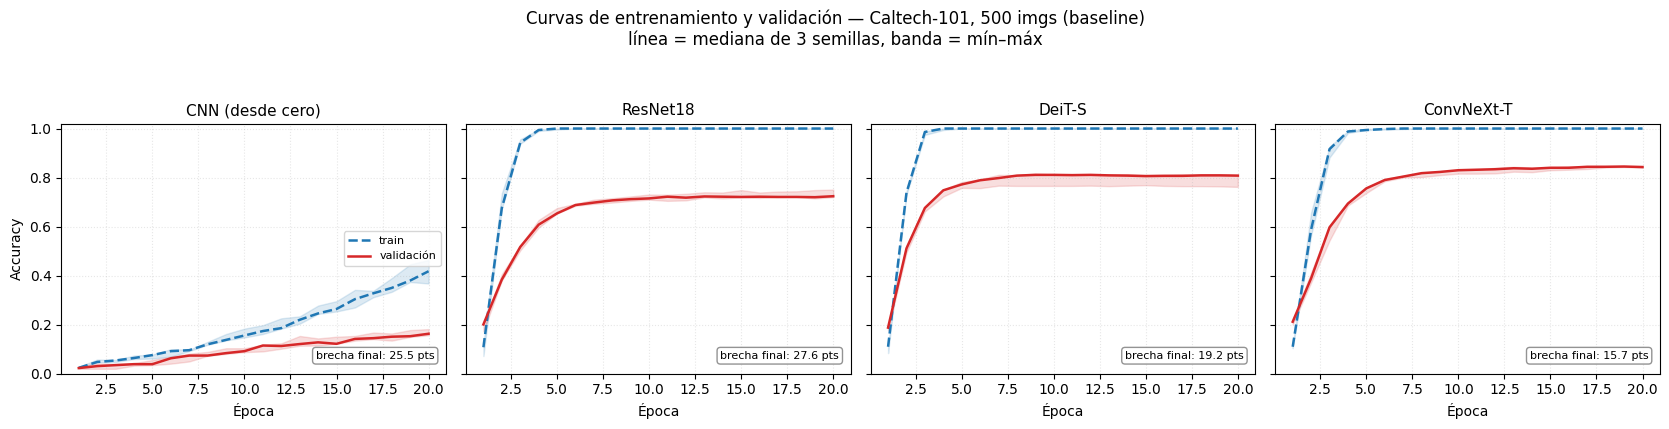

  guardado: figuras/fig3b_curvas_caltech2000.png y .pdf


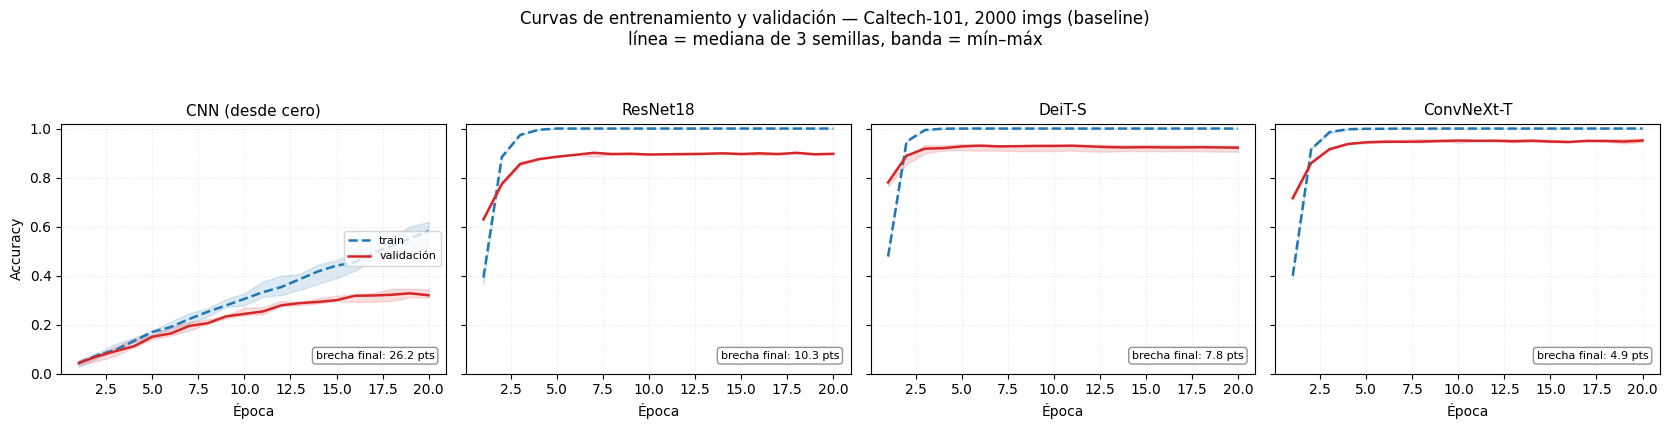

In [6]:
# FIGURA 3: curvas train vs val, un panel por modelo
def figura_curvas(dataset="caltech101", train_size=2000, aug=0,
                  nombre_fig=None):
    disponibles = [(b, k) for b, k in MODELOS.items()
                   if historiales_de(k, dataset, train_size, aug) is not None]
    if not disponibles:
        print("No hay historiales para esa combinación.")
        return

    fig, axes = plt.subplots(1, len(disponibles),
                             figsize=(4.2*len(disponibles), 4), sharey=True)
    if len(disponibles) == 1:
        axes = [axes]

    for ax, (bonito, key) in zip(axes, disponibles):
        h = historiales_de(key, dataset, train_size, aug)
        ep = np.arange(1, h["train_acc"].shape[1] + 1)

        for met, color, etq in [("train_acc", "#1f77b4", "train"),
                                ("val_acc",   "#d62728", "validación")]:
            if met not in h:
                continue
            med = np.median(h[met], axis=0)
            lo, hi = h[met].min(axis=0), h[met].max(axis=0)
            estilo = "--" if met == "train_acc" else "-"
            ax.plot(ep, med, estilo, color=color, linewidth=1.8, label=etq)
            ax.fill_between(ep, lo, hi, color=color, alpha=0.15)

        # brecha final = overfitting, anotada
        if "train_acc" in h and "val_acc" in h:
            gap = np.median(h["train_acc"], axis=0)[-1] - np.median(h["val_acc"], axis=0)[-1]
            ax.annotate(f"brecha final: {gap*100:.1f} pts",
                        xy=(0.97, 0.06), xycoords="axes fraction",
                        ha="right", fontsize=8,
                        bbox=dict(boxstyle="round,pad=0.3", fc="white",
                                  ec="gray", alpha=0.85))
        ax.set_title(bonito, fontsize=11)
        ax.set_xlabel("Época")
        ax.grid(alpha=0.3, linestyle=":")
        ax.set_ylim(0, 1.02)
    axes[0].set_ylabel("Accuracy")
    axes[0].legend(fontsize=8, loc="center right")

    fase = "con augmentation" if aug else "baseline"
    fig.suptitle(f"Curvas de entrenamiento y validación — "
                 f"{NOMBRE_DS[dataset]}, {train_size} imgs ({fase})\n"
                 f"línea = mediana de 3 semillas, banda = mín–máx",
                 fontsize=12, y=1.06)
    plt.tight_layout()
    if nombre_fig:
        guardar(fig, nombre_fig)
    plt.show()


# la comparación más informativa: pocos datos, donde el overfitting se ve
figura_curvas("caltech101", 500,  aug=0, nombre_fig="fig3a_curvas_caltech500")
figura_curvas("caltech101", 2000, aug=0, nombre_fig="fig3b_curvas_caltech2000")

### Figura 3c — Curvas: el augmentation visto en el tiempo

Mismo modelo, mismo dataset, **con y sin** augmentation. Aquí se ve *por qué*
el augmentation ayuda o no: si la brecha train–val se cierra (regularización
efectiva) o si la curva de train nunca despega (el modelo ya estaba en
underfitting y el augmentation lo empeora).

  guardado: figuras/fig3c_curvas_aug_convnext.png y .pdf


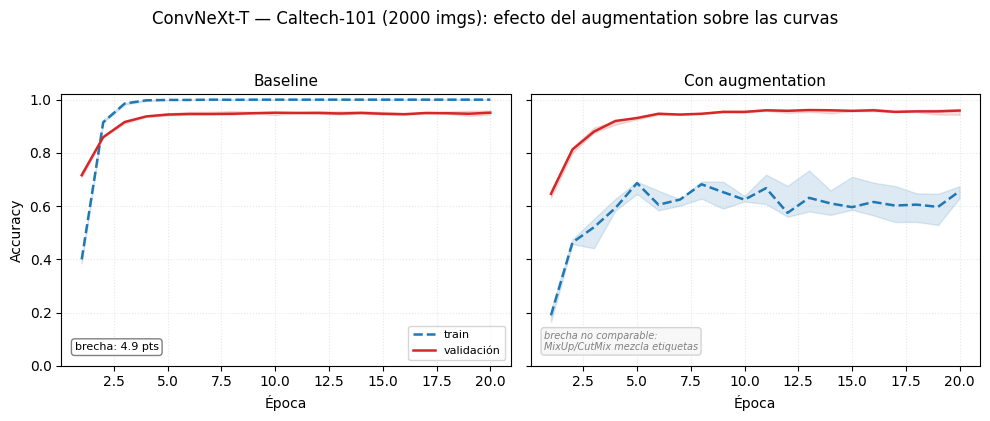

  guardado: figuras/fig3d_curvas_aug_cnn.png y .pdf


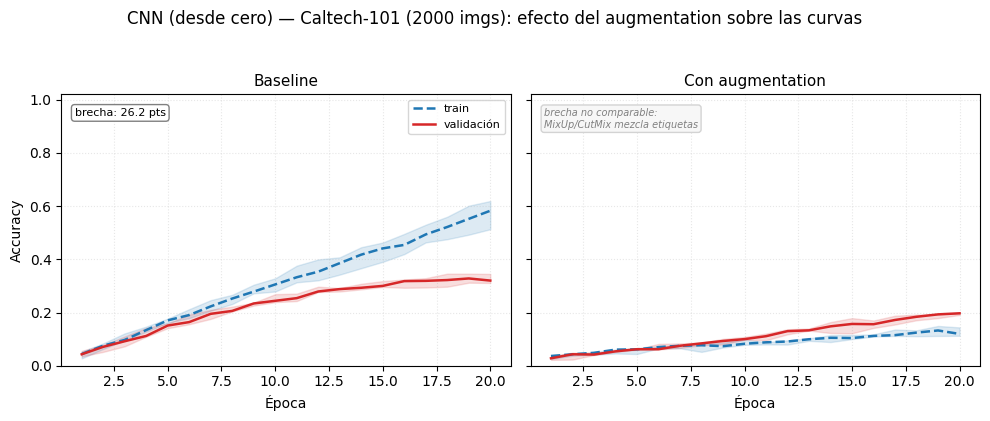

In [7]:
# FIGURA 3c/3d: efecto del augmentation sobre las curvas, mismo modelo
#
# OJO METODOLÓGICO: con MixUp/CutMix la `train_acc` se mide contra una de las
# dos etiquetas mezcladas, así que NO es comparable con la del baseline (puede
# quedar por debajo de la validación y dar una "brecha" negativa sin sentido).
# Por eso la brecha se anota SOLO en el panel baseline.
def curvas_aug_vs_base(model_key, dataset="caltech101", train_size=2000,
                       nombre_fig=None):
    hb = historiales_de(model_key, dataset, train_size, aug=0)
    ha = historiales_de(model_key, dataset, train_size, aug=1)
    if hb is None or ha is None:
        print(f"Faltan historiales para {model_key} ({dataset}, {train_size}).")
        return

    bonito = [b for b, k in MODELOS.items() if k == model_key][0]
    fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

    for ax, h, titulo, es_base in [(axes[0], hb, "Baseline", True),
                                   (axes[1], ha, "Con augmentation", False)]:
        ep = np.arange(1, h["train_acc"].shape[1] + 1)
        for met, color, etq in [("train_acc", "#1f77b4", "train"),
                                ("val_acc",   "#d62728", "validación")]:
            med = np.median(h[met], axis=0)
            ax.plot(ep, med, "--" if met == "train_acc" else "-",
                    color=color, linewidth=1.8, label=etq)
            ax.fill_between(ep, h[met].min(axis=0), h[met].max(axis=0),
                            color=color, alpha=0.15)

        # elegir esquina libre: si las curvas terminan altas, anotar abajo
        alto = max(np.median(h["train_acc"], axis=0)[-1],
                   np.median(h["val_acc"], axis=0)[-1])
        if alto > 0.7:
            pos, va = (0.03, 0.05), "bottom"   # curvas arriba -> anotar abajo
        else:
            pos, va = (0.03, 0.95), "top"      # curvas abajo -> anotar arriba

        if es_base:
            gap = (np.median(h["train_acc"], axis=0)[-1] -
                   np.median(h["val_acc"], axis=0)[-1])
            ax.annotate(f"brecha: {gap*100:.1f} pts", xy=pos,
                        xycoords="axes fraction", ha="left", va=va, fontsize=8,
                        bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray"))
        else:
            ax.annotate("brecha no comparable:\nMixUp/CutMix mezcla etiquetas",
                        xy=pos, xycoords="axes fraction",
                        ha="left", va=va, fontsize=7, style="italic", color="gray",
                        bbox=dict(boxstyle="round,pad=0.3", fc="#f7f7f7",
                                  ec="lightgray"))

        ax.set_title(titulo, fontsize=11)
        ax.set_xlabel("Época"); ax.grid(alpha=0.3, linestyle=":")
        ax.set_ylim(0, 1.02)

    axes[0].set_ylabel("Accuracy"); axes[0].legend(fontsize=8)
    fig.suptitle(f"{bonito} — {NOMBRE_DS[dataset]} ({train_size} imgs): "
                 f"efecto del augmentation sobre las curvas", y=1.04, fontsize=12)
    plt.tight_layout()
    if nombre_fig:
        guardar(fig, nombre_fig)
    plt.show()


# MISMO dataset y tamaño en ambas: lo único que varía es la arquitectura.
# Caltech-101 es donde el contraste es máximo (ConvNeXt +1.0 pts, CNN -13.0).
curvas_aug_vs_base("convnext", "caltech101", 2000, "fig3c_curvas_aug_convnext")
curvas_aug_vs_base("cnn",      "caltech101", 2000, "fig3d_curvas_aug_cnn")

## Figura 4 — Estabilidad y overfitting

Dos aspectos clave del análisis:
- **Estabilidad del entrenamiento al reducir el dataset** = desviación estándar
  entre semillas. Barra alta = resultado impredecible según la semilla.
- **Brecha de overfitting** = train_acc − test_acc.

⚠ La brecha **solo se grafica para el baseline**. Con MixUp/CutMix la
`train_acc` se mide contra una etiqueta mezclada, así que el gap de las
corridas con `aug=1` no es comparable.

  guardado: figuras/fig4_estabilidad_y_overfitting.png y .pdf


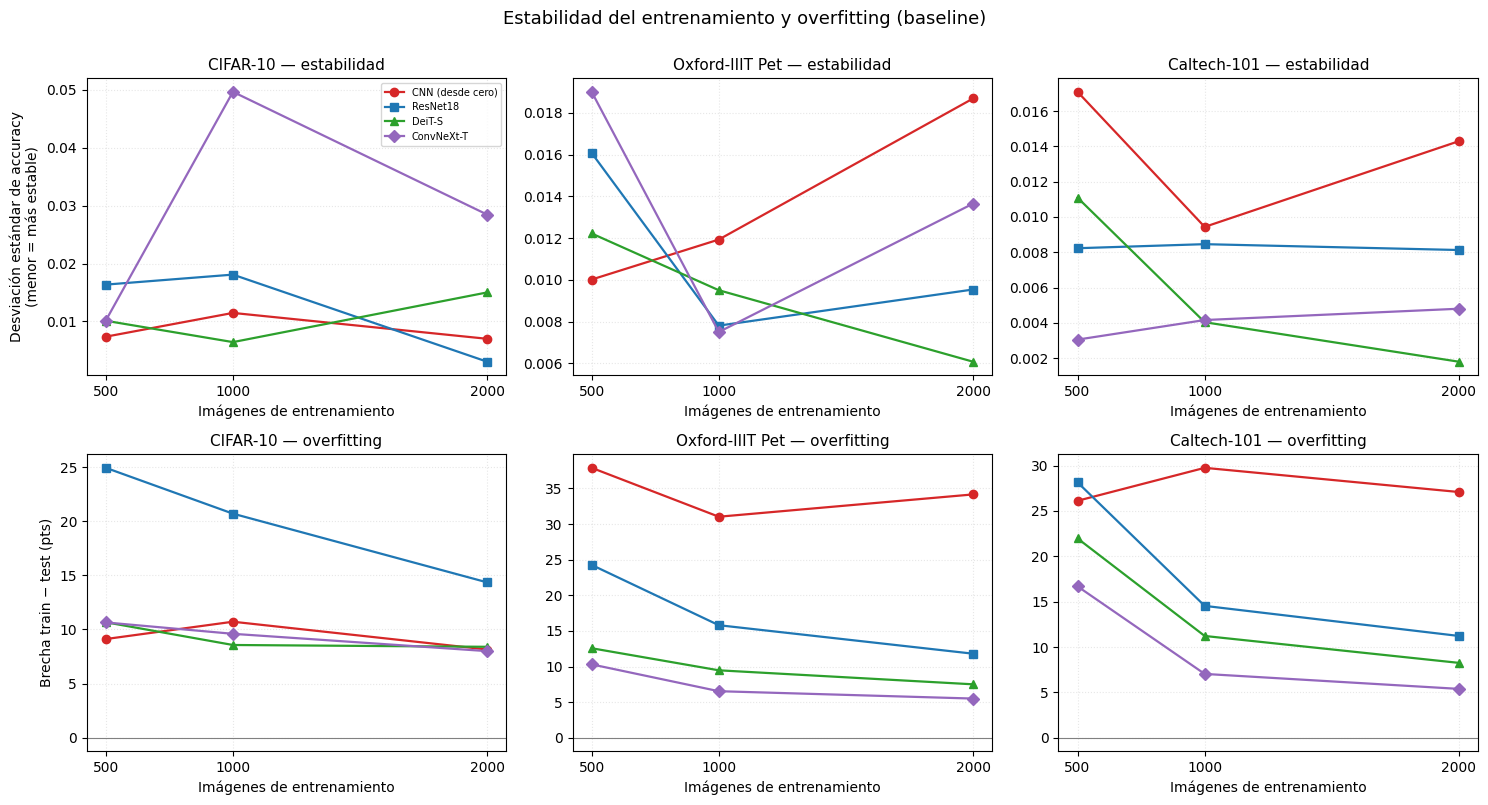

In [8]:
# FIGURA 4: estabilidad (std) y overfitting, ambos solo baseline
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

# fila 1: estabilidad = std entre semillas
for ax, ds in zip(axes[0], DATASETS):
    sub = res_base[res_base["dataset"] == ds]
    for m in ORDEN_MODELOS:
        s = sub[sub["modelo"] == m].sort_values("train_size")
        if len(s):
            ax.plot(s["train_size"], s["acc_std"], marker=MARCA[m],
                    color=COLOR[m], linewidth=1.6, label=m)
    ax.set_title(f"{NOMBRE_DS[ds]} — estabilidad", fontsize=11)
    ax.set_xticks([500, 1000, 2000]); ax.grid(alpha=0.3, linestyle=":")
    ax.set_xlabel("Imágenes de entrenamiento")
axes[0][0].set_ylabel("Desviación estándar de accuracy\n(menor = más estable)")
axes[0][0].legend(fontsize=7)

# fila 2: brecha de overfitting
for ax, ds in zip(axes[1], DATASETS):
    sub = res_base[res_base["dataset"] == ds]
    for m in ORDEN_MODELOS:
        s = sub[sub["modelo"] == m].sort_values("train_size")
        if len(s):
            ax.plot(s["train_size"], s["gap"], marker=MARCA[m],
                    color=COLOR[m], linewidth=1.6, label=m)
    ax.set_title(f"{NOMBRE_DS[ds]} — overfitting", fontsize=11)
    ax.set_xticks([500, 1000, 2000]); ax.grid(alpha=0.3, linestyle=":")
    ax.set_xlabel("Imágenes de entrenamiento")
    ax.axhline(0, color="gray", linewidth=0.8)
axes[1][0].set_ylabel("Brecha train − test (pts)")

fig.suptitle("Estabilidad del entrenamiento y overfitting (baseline)",
             fontsize=13, y=1.00)
plt.tight_layout()
guardar(fig, "fig4_estabilidad_y_overfitting")
plt.show()

## Tablas

Listas para pegar en LaTeX (`to_latex()`) o copiar como texto.

In [9]:
# TABLA 1: resultados principales (accuracy media ± std, baseline)
def tabla_metrica(d, met="acc", std="acc_std", decimales=3):
    t = d.copy()
    t["celda"] = (t[met].round(decimales).astype(str) + " ± " +
                  t[std].fillna(0).round(decimales).astype(str))
    piv = t.pivot_table(index="modelo", columns=["dataset", "train_size"],
                        values="celda", aggfunc="first")
    piv = piv.reindex([m for m in ORDEN_MODELOS if m in piv.index])
    return piv.reindex(columns=pd.MultiIndex.from_product(
        [DATASETS, [500, 1000, 2000]], names=["dataset", "train_size"]))


print("TABLA 1 — Accuracy de test (media ± std sobre 3 semillas), BASELINE")
print("="*100)
t1 = tabla_metrica(res_base, "acc", "acc_std")
print(t1.to_string())

print("\n\nTABLA 2 — F1-macro (media ± std), BASELINE")
print("="*100)
t2 = tabla_metrica(res_base, "f1", "f1_std")
print(t2.to_string())

if len(aug):
    print("\n\nTABLA 3 — Accuracy con AUGMENTATION (media ± std)")
    print("="*100)
    print(tabla_metrica(res_aug, "acc", "acc_std").to_string())

# exportar a LaTeX y CSV
t1.to_csv(FIG_DIR / "tabla1_accuracy_baseline.csv")
with open(FIG_DIR / "tabla1_accuracy_baseline.tex", "w") as f:
    f.write(t1.to_latex(caption="Accuracy de test (media ± std, 3 semillas).",
                        label="tab:accuracy", na_rep="--"))
print("\n\nExportadas a figuras/tabla1_accuracy_baseline.{csv,tex}")

TABLA 1 — Accuracy de test (media ± std sobre 3 semillas), BASELINE
dataset                 cifar10                                          pet                                   caltech101                              
train_size                 500            1000           2000           500            1000           2000           500            1000           2000
modelo                                                                                                                                                 
CNN (desde cero)   0.35 ± 0.007  0.401 ± 0.011  0.457 ± 0.007   0.084 ± 0.01  0.106 ± 0.012  0.149 ± 0.019  0.156 ± 0.017  0.216 ± 0.009  0.301 ± 0.014
ResNet18          0.751 ± 0.016  0.791 ± 0.018  0.856 ± 0.003  0.757 ± 0.016  0.842 ± 0.008   0.882 ± 0.01  0.718 ± 0.008  0.855 ± 0.008  0.888 ± 0.008
DeiT-S             0.893 ± 0.01  0.914 ± 0.006  0.912 ± 0.015  0.874 ± 0.012   0.905 ± 0.01  0.925 ± 0.006   0.78 ± 0.011  0.888 ± 0.004  0.918 ± 0.002
ConvNeXt-T         0

## Resumen de hallazgos (generado desde los datos)

Extrae de los datos los números clave que sostienen cada conclusión del
proyecto, para no citar nada de memoria.

In [10]:
# extraer los números que sostienen las conclusiones
print("="*72)
print("NÚMEROS CLAVE PARA LA DISCUSIÓN")
print("="*72)

# 1) valor del transfer learning
print("\n[1] Efecto del transfer learning (CNN desde cero vs preentrenados)")
for ds in DATASETS:
    s = res_base[(res_base["dataset"] == ds) & (res_base["train_size"] == 2000)]
    if "CNN (desde cero)" not in s["modelo"].values:
        continue
    cnn = s[s["modelo"] == "CNN (desde cero)"]["acc"].iloc[0]
    pre = s[s["modelo"] != "CNN (desde cero)"]["acc"]
    if len(pre):
        print(f"   {NOMBRE_DS[ds]:18} CNN {cnn:.3f} vs preentrenados "
              f"{pre.mean():.3f}  (+{(pre.mean()-cnn)*100:.1f} pts)")

# 2) signo del augmentation por modelo
print("\n[2] Efecto del augmentation: media del delta por modelo")
for m in ORDEN_MODELOS:
    s = delta[delta["modelo"] == m]
    if not len(s):
        continue
    med = s["delta_acc"].mean()*100
    pos = (s["delta_acc"] > 0).sum()
    signo = "AYUDA" if med > 0.5 else ("PERJUDICA" if med < -0.5 else "neutro")
    print(f"   {m:18} {med:+5.1f} pts en promedio  "
          f"({pos}/{len(s)} combinaciones positivas)  -> {signo}")

# 3) donde mas ayuda el augmentation (por tamaño)
print("\n[3] ¿El augmentation ayuda más con pocos datos? (solo preentrenados)")
pre_delta = delta[delta["modelo"] != "CNN (desde cero)"]
for t in [500, 1000, 2000]:
    s = pre_delta[pre_delta["train_size"] == t]
    if len(s):
        print(f"   {t:5} imgs: delta medio {s['delta_acc'].mean()*100:+5.2f} pts")

# 4) estabilidad: donde la semilla importa mas
print("\n[4] Inestabilidad máxima (mayor std entre semillas, baseline)")
peor = res_base.nlargest(4, "acc_std")[["modelo","dataset","train_size","acc","acc_std"]]
for _, r in peor.iterrows():
    print(f"   {r['modelo']:18} {r['dataset']:11} n={int(r['train_size']):5} "
          f"acc={r['acc']:.3f} ± {r['acc_std']:.3f}")

# 5) overfitting: baja con mas datos?
print("\n[5] Brecha de overfitting: 500 -> 2000 imgs (baseline)")
for m in ORDEN_MODELOS:
    s = res_base[res_base["modelo"] == m]
    if not len(s):
        continue
    g500  = s[s["train_size"] == 500]["gap"].mean()
    g2000 = s[s["train_size"] == 2000]["gap"].mean()
    print(f"   {m:18} {g500:5.1f} -> {g2000:5.1f} pts  ({g2000-g500:+.1f})")

print("\n" + "="*72)
print("Figuras y tablas guardadas en ./figuras/")
print("="*72)

NÚMEROS CLAVE PARA LA DISCUSIÓN

[1] Efecto del transfer learning (CNN desde cero vs preentrenados)
   CIFAR-10           CNN 0.457 vs preentrenados 0.894  (+43.7 pts)
   Oxford-IIIT Pet    CNN 0.149 vs preentrenados 0.916  (+76.7 pts)
   Caltech-101        CNN 0.301 vs preentrenados 0.917  (+61.7 pts)

[2] Efecto del augmentation: media del delta por modelo
   CNN (desde cero)    -5.1 pts en promedio  (0/9 combinaciones positivas)  -> PERJUDICA
   ResNet18            -0.8 pts en promedio  (5/9 combinaciones positivas)  -> PERJUDICA
   DeiT-S              +1.0 pts en promedio  (5/9 combinaciones positivas)  -> AYUDA
   ConvNeXt-T          +1.9 pts en promedio  (8/9 combinaciones positivas)  -> AYUDA

[3] ¿El augmentation ayuda más con pocos datos? (solo preentrenados)
     500 imgs: delta medio +1.72 pts
    1000 imgs: delta medio +0.41 pts
    2000 imgs: delta medio -0.09 pts

[4] Inestabilidad máxima (mayor std entre semillas, baseline)
   ConvNeXt-T         cifar10     n= 1000 acc=0

## Figura 5 — Tamaño del modelo vs desempeño (eficiencia)

El número de parámetros ya está en el CSV (`n_params`), guardado por cada
corrida. Varía un poco por dataset porque la capa final se adapta al número
de clases (10 / 37 / 101).

Esta figura contextualiza la comparación: la CNN pequeña no solo carece de
pretraining, además tiene **órdenes de magnitud menos parámetros**. Mostrarlo
hace la discusión más honesta — y permite hablar de *accuracy por parámetro*,
no solo de accuracy cruda.

PARÁMETROS ENTRENABLES por modelo y dataset
dataset           caltech101     cifar10         pet
modelo                                              
CNN (desde cero)   2,216,613     620,362   2,200,165
ResNet18          11,228,325  11,181,642  11,195,493
DeiT-S            21,704,549  21,669,514  21,679,909
ConvNeXt-T        27,897,797  27,827,818  27,848,581

(varía por dataset: la capa final se ajusta al nº de clases)

Resumen para el paper (rango de parámetros):
  CNN (desde cero)   0.62 – 2.22 M
  ResNet18           11.18 – 11.23 M
  DeiT-S             21.67 – 21.70 M
  ConvNeXt-T         27.83 – 27.90 M
  guardado: figuras/fig5_parametros_vs_accuracy.png y .pdf


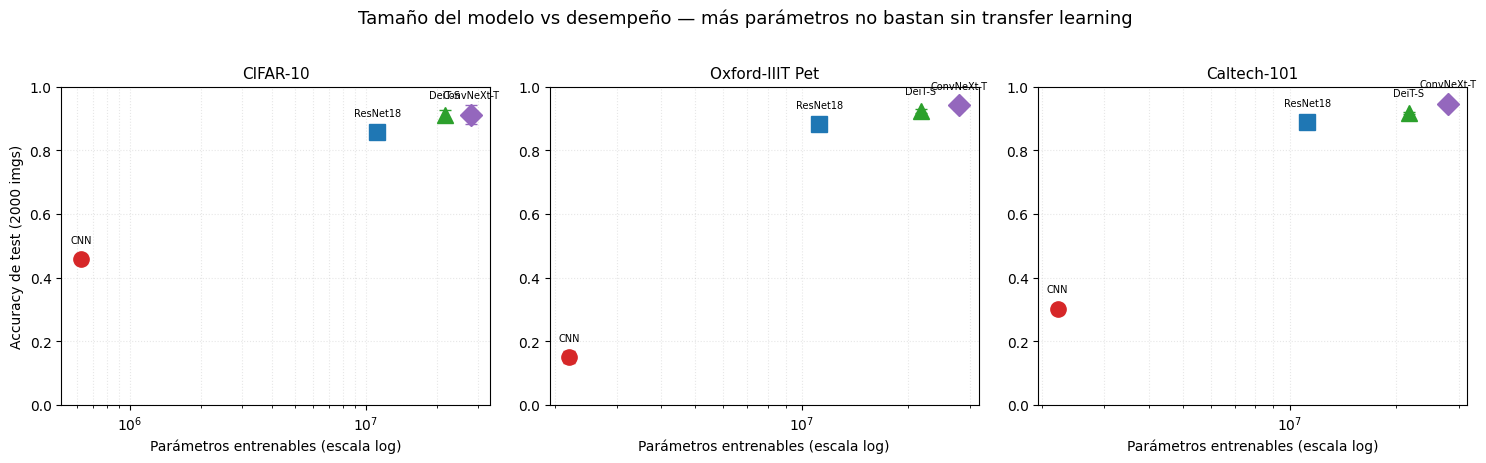



Eficiencia: accuracy por millón de parámetros (2000 imgs)

  CIFAR-10:
     CNN (desde cero)   acc=0.457    0.62M  -> 0.7367 acc/M
     ResNet18           acc=0.857   11.18M  -> 0.0766 acc/M
     DeiT-S             acc=0.912   21.67M  -> 0.0421 acc/M
     ConvNeXt-T         acc=0.913   27.83M  -> 0.0328 acc/M

  Oxford-IIIT Pet:
     ResNet18           acc=0.882   11.20M  -> 0.0788 acc/M
     CNN (desde cero)   acc=0.149    2.20M  -> 0.0677 acc/M
     DeiT-S             acc=0.925   21.68M  -> 0.0427 acc/M
     ConvNeXt-T         acc=0.942   27.85M  -> 0.0338 acc/M

  Caltech-101:
     CNN (desde cero)   acc=0.301    2.22M  -> 0.1356 acc/M
     ResNet18           acc=0.888   11.23M  -> 0.0791 acc/M
     DeiT-S             acc=0.917   21.70M  -> 0.0423 acc/M
     ConvNeXt-T         acc=0.946   27.90M  -> 0.0339 acc/M


Exportada: figuras/tabla_parametros.csv


In [11]:
# TABLA + FIGURA 5: parámetros por modelo y eficiencia
params = (df.groupby(["modelo", "dataset"])["n_params"]
            .first().unstack())
params = params.reindex([m for m in ORDEN_MODELOS if m in params.index])

print("PARÁMETROS ENTRENABLES por modelo y dataset")
print("="*70)
print(params.map(lambda v: f"{int(v):,}" if pd.notna(v) else "--").to_string())

print("\n(varía por dataset: la capa final se ajusta al nº de clases)")
print("\nResumen para el paper (rango de parámetros):")
for m in params.index:
    v = params.loc[m].dropna()
    if len(v):
        lo, hi = int(v.min()), int(v.max())
        if lo == hi:
            print(f"  {m:18} {lo/1e6:.2f} M")
        else:
            print(f"  {m:18} {lo/1e6:.2f} – {hi/1e6:.2f} M")


# --- figura: params (log) vs accuracy, tamaño=2000, un panel por dataset ---
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, ds in zip(axes, DATASETS):
    s = res_base[(res_base["dataset"] == ds) & (res_base["train_size"] == 2000)]
    for m in ORDEN_MODELOS:
        r = s[s["modelo"] == m]
        if not len(r):
            continue
        p = df[(df["modelo"] == m) & (df["dataset"] == ds)]["n_params"].iloc[0]
        ax.errorbar(p, r["acc"].iloc[0], yerr=r["acc_std"].iloc[0],
                    marker=MARCA[m], color=COLOR[m], markersize=11,
                    capsize=4, linestyle="none", label=m)
        ax.annotate(m.split(" ")[0], (p, r["acc"].iloc[0]),
                    textcoords="offset points", xytext=(0, 12),
                    ha="center", fontsize=7)
    ax.set_xscale("log")
    ax.set_title(NOMBRE_DS[ds], fontsize=11)
    ax.set_xlabel("Parámetros entrenables (escala log)")
    ax.grid(alpha=0.3, linestyle=":", which="both")
    ax.set_ylim(0, 1.0)
axes[0].set_ylabel("Accuracy de test (2000 imgs)")
fig.suptitle("Tamaño del modelo vs desempeño — más parámetros no bastan "
             "sin transfer learning", fontsize=13, y=1.02)
plt.tight_layout()
guardar(fig, "fig5_parametros_vs_accuracy")
plt.show()


# --- accuracy por millón de parámetros: quién rinde más "por parámetro" ---
print("\n\nEficiencia: accuracy por millón de parámetros (2000 imgs)")
print("="*70)
for ds in DATASETS:
    print(f"\n  {NOMBRE_DS[ds]}:")
    s = res_base[(res_base["dataset"] == ds) & (res_base["train_size"] == 2000)]
    filas = []
    for m in ORDEN_MODELOS:
        r = s[s["modelo"] == m]
        if not len(r):
            continue
        p = df[(df["modelo"] == m) & (df["dataset"] == ds)]["n_params"].iloc[0]
        filas.append((m, r["acc"].iloc[0], p, r["acc"].iloc[0] / (p/1e6)))
    for m, acc, p, eff in sorted(filas, key=lambda x: -x[3]):
        print(f"     {m:18} acc={acc:.3f}  {p/1e6:6.2f}M  "
              f"-> {eff:.4f} acc/M")

# exportar tabla de parametros
params.to_csv(FIG_DIR / "tabla_parametros.csv")
print("\n\nExportada: figuras/tabla_parametros.csv")

In [12]:
# Genera tabla_f1_caltech.png : accuracy vs F1-macro en Caltech-101 (2000 imgs)
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

RESULTS_ROOT = Path("../resultados")
FIG_DIR = Path("../figuras"); FIG_DIR.mkdir(exist_ok=True)

MODELOS = {"CNN (desde cero)": "cnn", "ResNet18": "resnet",
           "DeiT-S": "deit", "ConvNeXt-T": "convnext"}
ORDEN = list(MODELOS)

DATASET   = "caltech101"
TRAIN_SZ  = 2000

# --- cargar y agregar las 3 semillas ---
filas = []
for bonito, key in MODELOS.items():
    ruta = RESULTS_ROOT / f"resultados_{key}" / f"resultados_{key}.csv"
    if not ruta.exists():
        print(f"FALTA: {ruta}"); continue
    d = pd.read_csv(ruta)
    if "aug" not in d.columns:
        d["aug"] = 0
    d = d.drop_duplicates(subset=["model","dataset","train_size","seed","aug"],
                          keep="last")
    d = d[(d["aug"] == 0) & (d["dataset"] == DATASET) &
          (d["train_size"] == TRAIN_SZ)]          # baseline, 2000 imgs
    if not len(d):
        print(f"sin filas para {bonito}"); continue
    filas.append({
        "modelo":  bonito,
        "acc":     d["test_acc"].mean(),      "acc_std": d["test_acc"].std(),
        "f1":      d["test_f1_macro"].mean(), "f1_std":  d["test_f1_macro"].std(),
        "n":       len(d),
    })

t = pd.DataFrame(filas)
t["delta"] = t["f1"] - t["acc"]          # negativo = F1 castiga clases raras
t = t.set_index("modelo").reindex([m for m in ORDEN if m in t["modelo"].values]
                                  if "modelo" in t else ORDEN).dropna(how="all")

print(f"Corridas por modelo (esperado 3): {t['n'].tolist()}")
print(t[["acc","acc_std","f1","f1_std","delta"]].round(4).to_string())

# --- dibujar la tabla como PNG ---
filas_txt = [[m,
              f"{r.acc:.3f} ± {r.acc_std:.3f}",
              f"{r.f1:.3f} ± {r.f1_std:.3f}",
              f"{r.delta:+.3f}"]
             for m, r in t.iterrows()]
cols = ["Modelo", "Accuracy", "F1-macro", "Δ (F1 − Acc)"]

fig, ax = plt.subplots(figsize=(8.2, 2.1))
ax.axis("off")
tab = ax.table(cellText=filas_txt, colLabels=cols,
               cellLoc="center", loc="center",
               colWidths=[0.30, 0.24, 0.24, 0.22])
tab.auto_set_font_size(False)
tab.set_fontsize(11)
tab.scale(1, 1.9)

AZUL = "#4a7ebb"
for (i, j), celda in tab.get_celld().items():
    celda.set_edgecolor("#b0b0b0")
    if i == 0:                                   # encabezado
        celda.set_facecolor(AZUL)
        celda.set_text_props(color="white", weight="bold")
    else:
        if i % 2 == 0:
            celda.set_facecolor("#f2f6fa")       # cebra
        if j == 0:
            celda.set_text_props(ha="left", weight="bold")
        if i == 1:                               # la CNN: fila destacada
            celda.set_facecolor("#fdeaea")

#fig.suptitle(f"Caltech-101 ({TRAIN_SZ} imgs, 101 clases desbalanceadas)",
#             fontsize=12, weight="bold", y=1.06)
#fig.text(0.5, -0.10,
#         "El F1-macro se aleja del accuracy cuanto peor es el modelo: sin pretraining,\n"
#         "el acierto se concentra en las clases mayoritarias.",
#         ha="center", fontsize=9, style="italic", color="#444444")

for ext in ("png", "pdf"):
    fig.savefig(FIG_DIR / f"tabla_f1_caltech.{ext}", dpi=300, bbox_inches="tight",
                facecolor="white")
print("\nGuardado: figuras/tabla_f1_caltech.png y .pdf")
plt.close(fig)

Corridas por modelo (esperado 3): [3, 3, 3, 3]
                     acc  acc_std      f1  f1_std   delta
modelo                                                   
CNN (desde cero)  0.3007   0.0143  0.2596  0.0134 -0.0411
ResNet18          0.8878   0.0081  0.8795  0.0094 -0.0083
DeiT-S            0.9175   0.0018  0.9141  0.0027 -0.0034
ConvNeXt-T        0.9462   0.0048  0.9436  0.0051 -0.0026

Guardado: figuras/tabla_f1_caltech.png y .pdf


In [13]:
# ============================================================
# SETUP imágenes crudas (para las figuras de muestras y de augmentation)
# No entrena. Solo carga los datasets para mostrarlos.
# ============================================================
from pathlib import Path
from torchvision import datasets, transforms
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

try:
    import google.colab
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

# busca la carpeta de datos que ya usaron los protocolos
_CANDIDATOS = [
    Path("../datos"),
    Path("../datos"),
    Path("/content/drive/MyDrive/Proyecto_DL/datos"),
]
DATA_ROOT = next((p for p in _CANDIDATOS if p.exists()), _CANDIDATOS[0])
DESCARGAR = EN_COLAB   # en Colab deja que torchvision baje lo que falte
print("DATA_ROOT =", DATA_ROOT.resolve(), "| descargar:", DESCARGAR)


def _cargar_ds_crudo(dataset_name):
    """Devuelve (ds, nombre_de_clase). Sin transform: entrega PIL Images."""
    root = str(DATA_ROOT)
    if dataset_name == "cifar10":
        ds = datasets.CIFAR10(root=root, train=True, download=DESCARGAR)
        nombre = lambda t: ds.classes[t]
    elif dataset_name == "pet":
        ds = datasets.OxfordIIITPet(root=root, split="trainval",
                                    target_types="category", download=DESCARGAR)
        nombre = lambda t: ds.classes[t]
    elif dataset_name == "caltech101":
        ds = datasets.Caltech101(root=root, target_type="category",
                                 download=DESCARGAR)
        nombre = lambda t: ds.categories[t]
    else:
        raise ValueError(dataset_name)
    return ds, nombre


def muestras(dataset_name, n=6, seed=0):
    """n imágenes RGB aleatorias con su nombre de clase. Salta BACKGROUND_Google."""
    ds, nombre = _cargar_ds_crudo(dataset_name)
    rng = np.random.RandomState(seed)
    orden = rng.permutation(len(ds))
    out = []
    for i in orden:
        img, t = ds[int(i)]
        cls = nombre(t)
        if cls == "BACKGROUND_Google":      # basura de Caltech, se ignora
            continue
        out.append((img.convert("RGB"), cls))
        if len(out) == n:
            break
    return out

print("Listo: usa muestras('cifar10'), muestras('pet'), muestras('caltech101').")

DATA_ROOT = ..\datos | descargar: False
Listo: usa muestras('cifar10'), muestras('pet'), muestras('caltech101').


<python>\site-packages\torchvision\datasets\cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


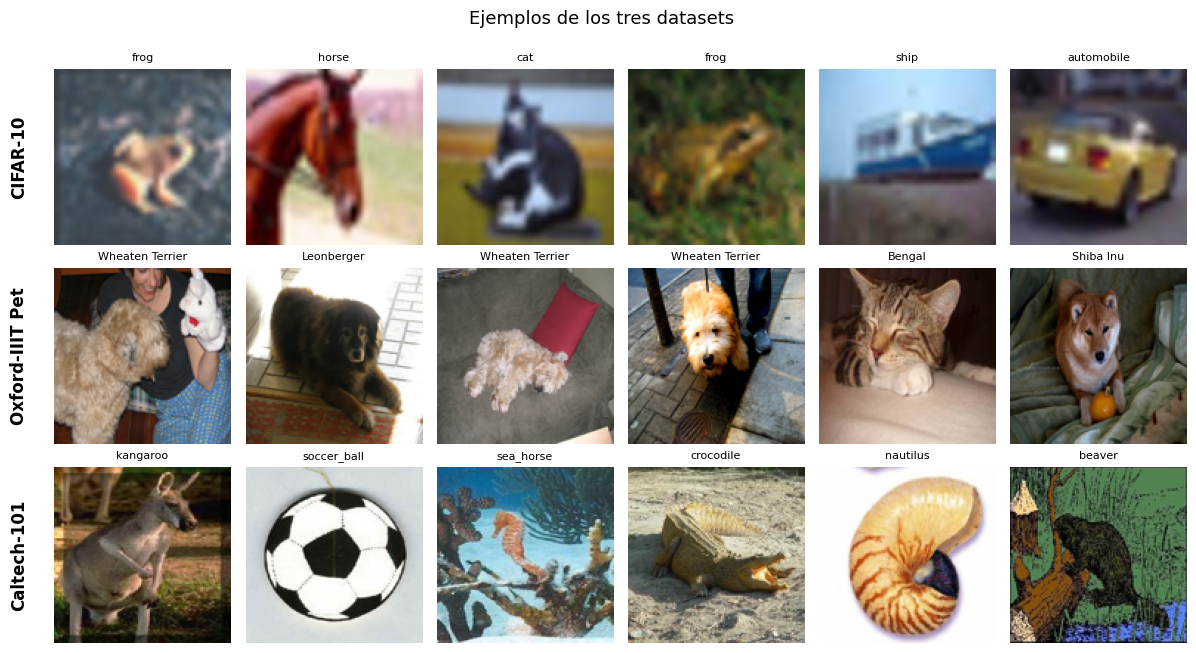

In [15]:
# FIGURA: ejemplos de los 3 datasets (una fila por dataset)
N = 6
fig, axes = plt.subplots(len(DATASETS), N, figsize=(2*N, 2*len(DATASETS)+0.5))
for fila, ds in enumerate(DATASETS):
    ejemplos = muestras(ds, n=N, seed=1)
    for col in range(N):
        ax = axes[fila][col]
        if col < len(ejemplos):
            img, cls = ejemplos[col]
            ax.imshow(img.resize((120, 120)))   # cuadrado uniforme solo para mostrar
            ax.set_title(cls, fontsize=8)
        ax.axis("off")
    axes[fila][0].set_ylabel(NOMBRE_DS[ds], fontsize=11, rotation=90,
                             labelpad=15, visible=True)
    # etiqueta del dataset a la izquierda
    axes[fila][0].text(-0.15, 0.5, NOMBRE_DS[ds], fontsize=12, fontweight="bold",
                       rotation=90, va="center", ha="right",
                       transform=axes[fila][0].transAxes)
fig.suptitle("Ejemplos de los tres datasets", fontsize=13, y=1.0)
plt.tight_layout()
plt.savefig(FIG_DIR / "muestras_datasets.png", dpi=200, bbox_inches="tight")
plt.show()

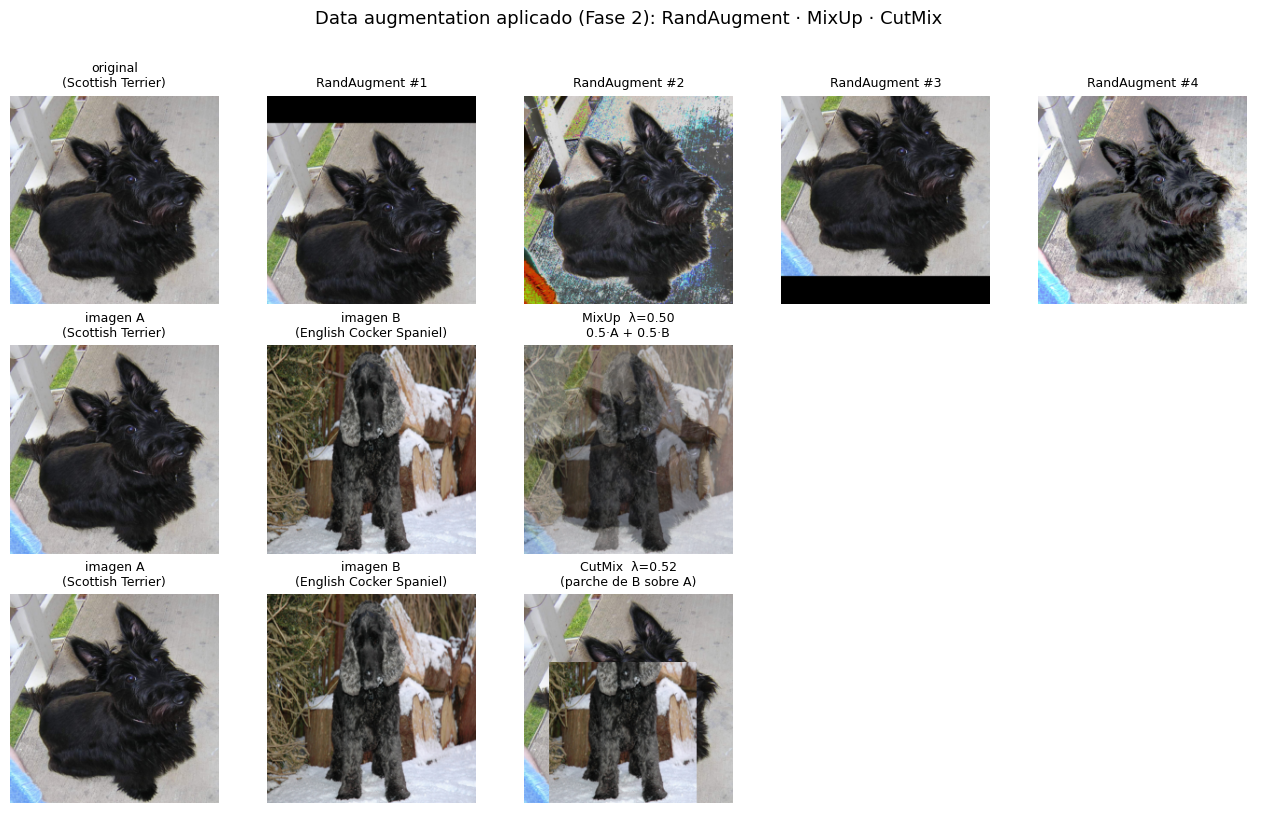

In [ ]:
# ============================================================
# FIGURA: RandAugment (con nombres de las operaciones) · MixUp · CutMix
# Reproduce el protocolo (num_ops=2, magnitude=9; MixUp α=0.2; CutMix α=1.0)
# Requiere la celda de setup de imágenes (define muestras() y DATA_ROOT).
# ============================================================
import torch, numpy as np
from PIL import Image
from torchvision import transforms
from torchvision.transforms import functional as F, InterpolationMode, autoaugment
import matplotlib.pyplot as plt

DS_DEMO, SEED_DEMO = "pet", 3
ej = muestras(DS_DEMO, n=2, seed=SEED_DEMO)
imgA, clsA = ej[0]
imgB, clsB = ej[1]
to_disp = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor()])
xA, xB = to_disp(imgA), to_disp(imgB)

# --- RandAugment replicado para PODER nombrar las operaciones ---
def randaugment_con_nombres(img, magnitude=9, num_ops=2, num_magnitude_bins=31, generator=None):
    fill = [0.0, 0.0, 0.0]
    op_meta = autoaugment.RandAugment(num_ops=num_ops, magnitude=magnitude
              )._augmentation_space(num_magnitude_bins, F.get_image_size(img)[::-1])
    nombres = []
    for _ in range(num_ops):
        idx = int(torch.randint(len(op_meta), (1,), generator=generator).item())
        op_name = list(op_meta.keys())[idx]
        magnitudes, signed = op_meta[op_name]
        mag = float(magnitudes[magnitude].item()) if magnitudes.ndim > 0 else 0.0
        if signed and torch.randint(2, (1,), generator=generator).item():
            mag *= -1.0
        img = autoaugment._apply_op(img, op_name, mag,
                                    interpolation=InterpolationMode.NEAREST, fill=fill)
        nombres.append(op_name if mag == 0.0 else f"{op_name} ({mag:+.1f})")
    return img, nombres

g = torch.Generator().manual_seed(SEED_DEMO)
variantes = []
for _ in range(4):
    aug_img, noms = randaugment_con_nombres(imgA, generator=g)
    variantes.append((to_disp(aug_img), "\n".join(noms)))   # nombre de las 2 ops

# --- MixUp (λ sorteado en el protocolo; aquí fijo 0.5 para que se VEA) ---
lam_mix = 0.5
xmix = lam_mix * xA + (1 - lam_mix) * xB

# --- CutMix (_rand_bbox exacto del protocolo) ---
def _rand_bbox(H, W, lam, rng):
    ratio = np.sqrt(1.0 - lam)
    cut_w, cut_h = int(W*ratio), int(H*ratio)
    cx, cy = rng.randint(W), rng.randint(H)
    x1 = np.clip(cx-cut_w//2, 0, W); y1 = np.clip(cy-cut_h//2, 0, H)
    x2 = np.clip(cx+cut_w//2, 0, W); y2 = np.clip(cy+cut_h//2, 0, H)
    return x1, y1, x2, y2
rng = np.random.RandomState(SEED_DEMO)
x1, y1, x2, y2 = _rand_bbox(224, 224, 0.5, rng)
xcut = xA.clone(); xcut[:, y1:y2, x1:x2] = xB[:, y1:y2, x1:x2]
lam_real = 1.0 - ((x2-x1)*(y2-y1)/(224*224))

def _show(ax, t, title, fs=9):
    ax.imshow(t.permute(1, 2, 0).clamp(0, 1).numpy())
    ax.set_title(title, fontsize=fs); ax.axis("off")

fig, axes = plt.subplots(3, 5, figsize=(13, 8.4))
# fila 1: RandAugment con las operaciones aplicadas
_show(axes[0, 0], xA, f"original\n({clsA})")
for i, (v, noms) in enumerate(variantes):
    _show(axes[0, i+1], v, f"RandAugment #{i+1}\n{noms}", fs=8)
# fila 2: MixUp
_show(axes[1, 0], xA, f"imagen A\n({clsA})")
_show(axes[1, 1], xB, f"imagen B\n({clsB})")
_show(axes[1, 2], xmix, f"MixUp  λ={lam_mix:.2f}\netiqueta: {lam_mix:.0%} {clsA} + {1-lam_mix:.0%} {clsB}")
axes[1, 3].axis("off"); axes[1, 4].axis("off")
# fila 3: CutMix
_show(axes[2, 0], xA, f"imagen A\n({clsA})")
_show(axes[2, 1], xB, f"imagen B\n({clsB})")
_show(axes[2, 2], xcut, f"CutMix  λ={lam_real:.2f}\n(parche de B sobre A; λ = área)")
axes[2, 3].axis("off"); axes[2, 4].axis("off")

fig.suptitle("Data augmentation aplicado (Fase 2): RandAugment · MixUp · CutMix",
             fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig(FIG_DIR/"augmentation_ilustrado.png", dpi=200, bbox_inches="tight")
plt.show()

MÉTRICAS FASE 2 (media ± std sobre 3 tamaños × 3 semillas)
          modelo    dataset  acc_base  acc_aug  acc_aug_std       Δ
CNN (desde cero) caltech101     0.224    0.112        0.050 -11.250
CNN (desde cero)    cifar10     0.403    0.371        0.053  -3.122
CNN (desde cero)        pet     0.113    0.104        0.028  -0.878
      ConvNeXt-T caltech101     0.903    0.927        0.032   2.417
      ConvNeXt-T    cifar10     0.899    0.931        0.016   3.167
      ConvNeXt-T        pet     0.924    0.926        0.022   0.167
          DeiT-S caltech101     0.862    0.897        0.033   3.539
          DeiT-S    cifar10     0.907    0.913        0.017   0.683
          DeiT-S        pet     0.902    0.888        0.023  -1.356
        ResNet18 caltech101     0.820    0.830        0.058   0.917
        ResNet18    cifar10     0.800    0.824        0.035   2.483
        ResNet18        pet     0.827    0.768        0.056  -5.867


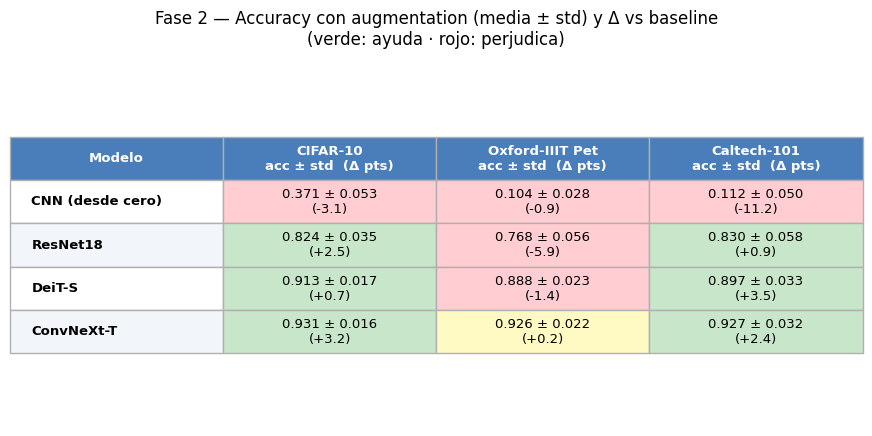


Caltech-101 (2000 imgs) — accuracy vs F1-macro (± std entre semillas)
                     acc  acc_std      f1  f1_std   delta
modelo                                                   
CNN (desde cero)  0.3007   0.0143  0.2596  0.0134 -4.1100
ResNet18          0.8878   0.0081  0.8795  0.0094 -0.8300
DeiT-S            0.9175   0.0018  0.9141  0.0027 -0.3367
ConvNeXt-T        0.9462   0.0048  0.9436  0.0051 -0.2600


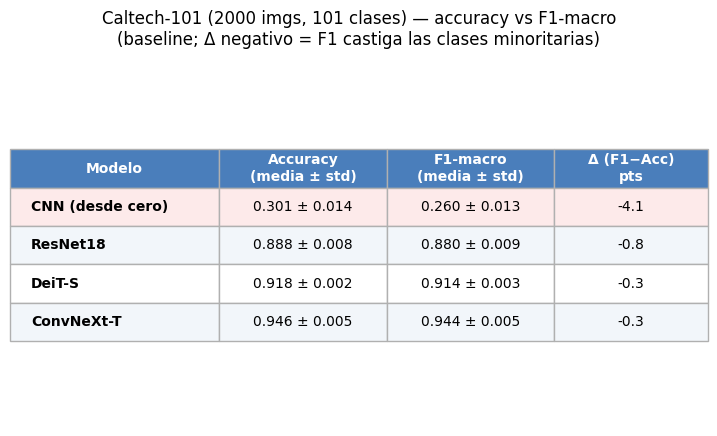


Guardado: figuras/tabla_fase2.png y figuras/tabla_f1_caltech.png


In [20]:
# ============================================================
# TABLAS PARA EL PÓSTER (2 en 1, mismo estilo) — celda autocontenida
#   1) Fase 2: accuracy con augmentation (media ± std) y Δ vs baseline
#   2) Caltech-101: accuracy vs F1-macro (media ± std) y Δ (F1 − Acc)
# Convenciones (iguales en las dos tablas):
#   ±  = desviación estándar (dispersión)
#   +/- = delta con signo (dirección del cambio, en puntos)
# ============================================================
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RESULTS_ROOT = Path("../resultados")
FIG_DIR = Path("../figuras"); FIG_DIR.mkdir(exist_ok=True)

MODELOS = {"CNN (desde cero)": "cnn", "ResNet18": "resnet",
           "DeiT-S": "deit", "ConvNeXt-T": "convnext"}
ORDEN = list(MODELOS)
DATASETS = ["cifar10", "pet", "caltech101"]
NOMBRE_DS = {"cifar10": "CIFAR-10", "pet": "Oxford-IIIT Pet",
             "caltech101": "Caltech-101"}

# --- cargar los 4 CSV ---
frames = []
for bonito, key in MODELOS.items():
    ruta = RESULTS_ROOT / f"resultados_{key}" / f"resultados_{key}.csv"
    if not ruta.exists():
        print(f"FALTA: {ruta}"); continue
    d = pd.read_csv(ruta)
    if "aug" not in d.columns:
        d["aug"] = 0
    d = d.drop_duplicates(subset=["model","dataset","train_size","seed","aug"],
                          keep="last")
    d["modelo"] = bonito
    frames.append(d)
df = pd.concat(frames, ignore_index=True)

# --- estilo compartido por las dos tablas ---
AZUL, CEBRA = "#4a7ebb", "#f2f6fa"
def estilar(tb):
    for (i, j), c in tb.get_celld().items():
        c.set_edgecolor("#b0b0b0")
        if i == 0:                                   # encabezado
            c.set_facecolor(AZUL); c.set_text_props(color="white", weight="bold")
        else:
            c.set_facecolor(CEBRA if i % 2 == 0 else "white")
            if j == 0: c.set_text_props(ha="left", weight="bold")

# ============================================================
# TABLA 1 — Fase 2
# nota: aquí el ± std resume las 9 corridas (3 tamaños × 3 semillas),
#       así que mezcla algo de variación por tamaño, no solo por semilla.
# ============================================================
def _stats(sub):
    return (sub.groupby(["modelo","dataset"])
               .agg(acc=("test_acc","mean"), acc_std=("test_acc","std"),
                    f1=("test_f1_macro","mean")).reset_index())

b = _stats(df[df["aug"] == 0]).set_index(["modelo","dataset"])
a = _stats(df[df["aug"] == 1]).set_index(["modelo","dataset"])
idx = b.index.intersection(a.index)
f2 = pd.DataFrame({"acc_base": b.loc[idx,"acc"], "acc_aug": a.loc[idx,"acc"],
                   "acc_aug_std": a.loc[idx,"acc_std"]}).reset_index()
f2["Δ"] = (f2.acc_aug - f2.acc_base) * 100

print("MÉTRICAS FASE 2 (media ± std sobre 3 tamaños × 3 semillas)")
print("=" * 70)
print(f2.round(3).to_string(index=False))

if len(f2):
    fig, ax = plt.subplots(figsize=(11, 0.85*len(ORDEN)+1.3)); ax.axis("off")
    cols = ["Modelo"] + [f"{NOMBRE_DS[d]}\nacc ± std  (Δ pts)" for d in DATASETS]
    celdas, overlay = [], {}
    for ii, m in enumerate(ORDEN):
        fila = [m]
        for jj, d in enumerate(DATASETS):
            r = f2[(f2.modelo == m) & (f2.dataset == d)]
            if len(r):
                acc, sd, dd = r.acc_aug.iloc[0], r.acc_aug_std.iloc[0], r["Δ"].iloc[0]
                fila.append(f"{acc:.3f} ± {sd:.3f}\n({dd:+.1f})")
                overlay[(ii+1, jj+1)] = ("#c8e6c9" if dd > 0.2 else
                                         ("#ffcdd2" if dd < -0.2 else "#fff9c4"))
            else:
                fila.append("--")
        celdas.append(fila)
    tb = ax.table(cellText=celdas, colLabels=cols, loc="center", cellLoc="center")
    tb.auto_set_font_size(False); tb.set_fontsize(9.5); tb.scale(1, 2.6)
    estilar(tb)
    for pos, color in overlay.items():
        tb[pos].set_facecolor(color)            # verde/rojo según el signo del Δ
    plt.title("Fase 2 — Accuracy con augmentation (media ± std) y Δ vs baseline\n"
              "(verde: ayuda · rojo: perjudica)", fontsize=12, pad=14)
    fig.savefig(FIG_DIR/"tabla_fase2.png", dpi=300, bbox_inches="tight", facecolor="white")
    # fig.savefig(FIG_DIR/"tabla_fase2.pdf", bbox_inches="tight", facecolor="white")  # vector
    plt.show()
else:
    print("Sin corridas con aug=1: corre la Fase 2 en los protocolos primero.")

# ============================================================
# TABLA 2 — Caltech-101: accuracy vs F1-macro (baseline, 2000 imgs)
# aquí el ± std es entre las 3 semillas (tamaño fijo = 2000)
# ============================================================
DATASET, TRAIN_SZ = "caltech101", 2000
sub = df[(df["aug"] == 0) & (df["dataset"] == DATASET) & (df["train_size"] == TRAIN_SZ)]
filas = []
for m in ORDEN:
    dd = sub[sub["modelo"] == m]
    if not len(dd):
        print(f"sin filas para {m}"); continue
    filas.append({"modelo": m,
                  "acc": dd["test_acc"].mean(),      "acc_std": dd["test_acc"].std(),
                  "f1":  dd["test_f1_macro"].mean(), "f1_std":  dd["test_f1_macro"].std()})
t = pd.DataFrame(filas).set_index("modelo")
t["delta"] = (t["f1"] - t["acc"]) * 100          # en puntos, como la otra tabla

print(f"\nCaltech-101 ({TRAIN_SZ} imgs) — accuracy vs F1-macro (± std entre semillas)")
print("=" * 70)
print(t[["acc","acc_std","f1","f1_std","delta"]].round(4).to_string())

filas_txt = [[m, f"{r.acc:.3f} ± {r.acc_std:.3f}",
              f"{r.f1:.3f} ± {r.f1_std:.3f}", f"{r.delta:+.1f}"]
             for m, r in t.iterrows()]
cols = ["Modelo", "Accuracy\n(media ± std)", "F1-macro\n(media ± std)", "Δ (F1−Acc)\npts"]
fig, ax = plt.subplots(figsize=(9, 0.85*len(t)+1.3)); ax.axis("off")
tb = ax.table(cellText=filas_txt, colLabels=cols, cellLoc="center", loc="center",
              colWidths=[0.30, 0.24, 0.24, 0.22])
tb.auto_set_font_size(False); tb.set_fontsize(10); tb.scale(1, 2.3)
estilar(tb)
for j in range(len(cols)):
    tb[1, j].set_facecolor("#fdeaea")            # CNN destacada
plt.title(f"Caltech-101 ({TRAIN_SZ} imgs, 101 clases) — accuracy vs F1-macro\n"
          "(baseline; Δ negativo = F1 castiga las clases minoritarias)",
          fontsize=12, pad=14)
fig.savefig(FIG_DIR/"tabla_f1_caltech.png", dpi=300, bbox_inches="tight", facecolor="white")
# fig.savefig(FIG_DIR/"tabla_f1_caltech.pdf", bbox_inches="tight", facecolor="white")  # vector
plt.show()

print("\nGuardado: figuras/tabla_fase2.png y figuras/tabla_f1_caltech.png")

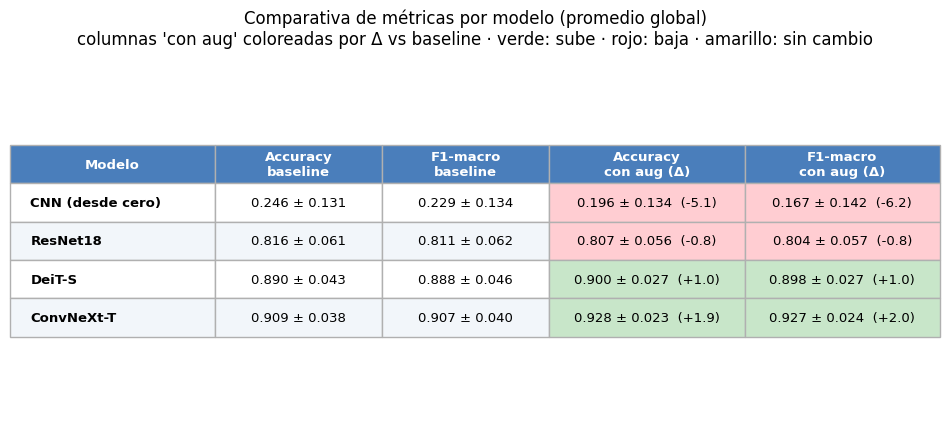

In [23]:
# ============================================================
# TABLA A — Comparativa de MÉTRICAS por modelo (visión global)
# accuracy vs F1-macro, baseline vs con aug. Promedio sobre
# 3 datasets × 3 tamaños × 3 semillas.
# Las columnas "con aug" se colorean según el Δ vs baseline:
#   verde = subió · rojo = bajó · amarillo = sin cambio (|Δ| ≤ 0.2 pts)
# ============================================================
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

RESULTS_ROOT = Path("../resultados")
FIG_DIR = Path("../figuras"); FIG_DIR.mkdir(exist_ok=True)
MODELOS = {"CNN (desde cero)": "cnn", "ResNet18": "resnet",
           "DeiT-S": "deit", "ConvNeXt-T": "convnext"}
ORDEN = list(MODELOS)

frames = []
for bonito, key in MODELOS.items():
    ruta = RESULTS_ROOT / f"resultados_{key}" / f"resultados_{key}.csv"
    if not ruta.exists():
        print(f"FALTA: {ruta}"); continue
    d = pd.read_csv(ruta)
    if "aug" not in d.columns: d["aug"] = 0
    d = d.drop_duplicates(subset=["model","dataset","train_size","seed","aug"], keep="last")
    d["modelo"] = bonito
    frames.append(d)
df = pd.concat(frames, ignore_index=True)

AZUL, CEBRA = "#4a7ebb", "#f2f6fa"
def estilar(tb):
    for (i, j), c in tb.get_celld().items():
        c.set_edgecolor("#b0b0b0")
        if i == 0:
            c.set_facecolor(AZUL); c.set_text_props(color="white", weight="bold")
        else:
            c.set_facecolor(CEBRA if i % 2 == 0 else "white")
            if j == 0: c.set_text_props(ha="left", weight="bold")

def color_delta(delta_pts):
    return "#c8e6c9" if delta_pts > 0.2 else ("#ffcdd2" if delta_pts < -0.2 else "#fff9c4")

def _m(sub):
    return (sub.groupby("modelo").agg(
        acc=("test_acc","mean"), acc_std=("test_acc","std"),
        f1=("test_f1_macro","mean"), f1_std=("test_f1_macro","std")).reset_index())

mb = _m(df[df["aug"] == 0]).set_index("modelo")
ma = _m(df[df["aug"] == 1]).set_index("modelo")

filas, overlay = [], {}
for r_i, m in enumerate(ORDEN):
    if m not in mb.index: continue
    fila = [m,
            f"{mb.loc[m,'acc']:.3f} ± {mb.loc[m,'acc_std']:.3f}",
            f"{mb.loc[m,'f1']:.3f} ± {mb.loc[m,'f1_std']:.3f}"]
    if m in ma.index:
        dacc = (ma.loc[m,'acc'] - mb.loc[m,'acc']) * 100
        df1  = (ma.loc[m,'f1']  - mb.loc[m,'f1'])  * 100
        fila += [f"{ma.loc[m,'acc']:.3f} ± {ma.loc[m,'acc_std']:.3f}  ({dacc:+.1f})",
                 f"{ma.loc[m,'f1']:.3f} ± {ma.loc[m,'f1_std']:.3f}  ({df1:+.1f})"]
        overlay[(r_i+1, 3)] = color_delta(dacc)   # columna Accuracy con aug
        overlay[(r_i+1, 4)] = color_delta(df1)    # columna F1-macro con aug
    else:
        fila += ["--", "--"]
    filas.append(fila)

cols = ["Modelo", "Accuracy\nbaseline", "F1-macro\nbaseline",
        "Accuracy\ncon aug (Δ)", "F1-macro\ncon aug (Δ)"]
fig, ax = plt.subplots(figsize=(12, 0.8*len(filas)+1.4)); ax.axis("off")
tb = ax.table(cellText=filas, colLabels=cols, loc="center", cellLoc="center",
              colWidths=[0.22, 0.18, 0.18, 0.21, 0.21])
tb.auto_set_font_size(False); tb.set_fontsize(9.5); tb.scale(1, 2.3)
estilar(tb)
for pos, color in overlay.items():
    tb[pos].set_facecolor(color)
plt.title("Comparativa de métricas por modelo (promedio global)\n"
          "columnas 'con aug' coloreadas por Δ vs baseline · "
          "verde: sube · rojo: baja · amarillo: sin cambio",
          fontsize=12, pad=14)
fig.savefig(FIG_DIR/"tabla_metricas.png", dpi=300, bbox_inches="tight", facecolor="white")
# fig.savefig(FIG_DIR/"tabla_metricas.pdf", bbox_inches="tight", facecolor="white")  # vector
plt.show()

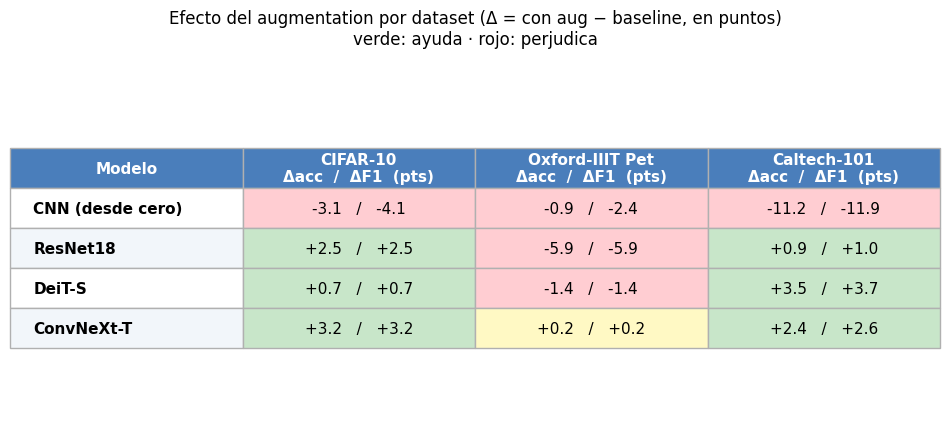

          modelo    dataset   dacc    df1
CNN (desde cero) caltech101 -11.25 -11.92
CNN (desde cero)    cifar10  -3.12  -4.10
CNN (desde cero)        pet  -0.88  -2.44
      ConvNeXt-T caltech101   2.42   2.58
      ConvNeXt-T    cifar10   3.17   3.15
      ConvNeXt-T        pet   0.17   0.18
          DeiT-S caltech101   3.54   3.72
          DeiT-S    cifar10   0.68   0.69
          DeiT-S        pet  -1.36  -1.37
        ResNet18 caltech101   0.92   1.02
        ResNet18    cifar10   2.48   2.52
        ResNet18        pet  -5.87  -5.91


In [22]:
# ============================================================
# TABLA B — Efecto del AUGMENTATION por DATASET
# Δ = (con aug) − (baseline), en puntos, para accuracy y F1-macro.
# Necesita las variables df, ORDEN, estilar, RESULTS_ROOT, FIG_DIR
# de la celda anterior (ejecutarla antes).
# ============================================================
DATASETS = ["cifar10", "pet", "caltech101"]
NOMBRE_DS = {"cifar10": "CIFAR-10", "pet": "Oxford-IIIT Pet",
             "caltech101": "Caltech-101"}

def _s(sub):
    return (sub.groupby(["modelo","dataset"]).agg(
        acc=("test_acc","mean"), f1=("test_f1_macro","mean")).reset_index())

b = _s(df[df["aug"] == 0]).set_index(["modelo","dataset"])
a = _s(df[df["aug"] == 1]).set_index(["modelo","dataset"])
idx = b.index.intersection(a.index)
d2 = pd.DataFrame({"dacc": (a.loc[idx,"acc"] - b.loc[idx,"acc"]) * 100,
                   "df1":  (a.loc[idx,"f1"]  - b.loc[idx,"f1"])  * 100}).reset_index()

fig, ax = plt.subplots(figsize=(12, 0.85*len(ORDEN)+1.4)); ax.axis("off")
cols = ["Modelo"] + [f"{NOMBRE_DS[d]}\nΔacc  /  ΔF1  (pts)" for d in DATASETS]
celdas, overlay = [], {}
for ii, m in enumerate(ORDEN):
    fila = [m]
    for jj, d in enumerate(DATASETS):
        r = d2[(d2.modelo == m) & (d2.dataset == d)]
        if len(r):
            r = r.iloc[0]
            fila.append(f"{r.dacc:+.1f}   /   {r.df1:+.1f}")
            overlay[(ii+1, jj+1)] = ("#c8e6c9" if r.dacc > 0.2 else
                                     ("#ffcdd2" if r.dacc < -0.2 else "#fff9c4"))
        else:
            fila.append("--")
    celdas.append(fila)
tb = ax.table(cellText=celdas, colLabels=cols, loc="center", cellLoc="center")
tb.auto_set_font_size(False); tb.set_fontsize(11); tb.scale(1, 2.4)
estilar(tb)
for pos, color in overlay.items():
    tb[pos].set_facecolor(color)
plt.title("Efecto del augmentation por dataset (Δ = con aug − baseline, en puntos)\n"
          "verde: ayuda · rojo: perjudica",
          fontsize=12, pad=14)
fig.savefig(FIG_DIR/"tabla_aug_por_dataset.png", dpi=300, bbox_inches="tight", facecolor="white")
# fig.savefig(FIG_DIR/"tabla_aug_por_dataset.pdf", bbox_inches="tight", facecolor="white")  # vector
plt.show()
print(d2.round(2).to_string(index=False))